## Parcial práctico DDYA 2026-2: Colas de prioridad y Árbol de Expansión Mínima
Escuela Colombiana de Ingeniería Julio Garavito · Entrega: `parcial_prioridad_mst.ipynb`

**Instrucción:** completa esta plantilla con tu diseño y desarrollo.

In [ ]:
# @title Ingrese datos
nombre_estudiante = "Alejandro Tellez" # @param {"type":"string"}
carnet = 1000113658 # @param {"type":"integer"}

## 1) Descripción del problema **[1 pts]**

Una empresa tiene dos necesidades técnicas que se resuelven con estructuras de datos y grafos:

1. **Administrar tareas técnicas según su prioridad.** Cada tarea tiene un código, un nombre y un valor de prioridad (a mayor valor, más urgente). Hay que atender siempre primero la tarea más urgente y poder agregar tareas nuevas en cualquier momento. Para esto se usa una **Max-Priority Queue** implementada sobre un **Max-Heap** (sin `heapq`).
2. **Conectar seis dispositivos usando la menor cantidad total de cable.** Cada dispositivo tiene una posición $(x, y)$ en un plano; conectar dos dispositivos cuesta la distancia euclidiana entre ellos. Se modela como un grafo completo ponderado y se busca su **Árbol de Expansión Mínima (MST)** con el algoritmo de **Kruskal** implementado a mano.

**Entradas:** 6 tareas con prioridad, 1 tarea urgente adicional (T07) y 6 dispositivos con coordenadas.
**Salidas:** el Max-Heap (arreglo y árbol) en cada etapa, el orden de procesamiento de tareas, las 5 conexiones del MST y la longitud total de cable.

## 2) Requerimientos **[2 pts]**

**Funcionales**

- **RF1.** Construir un Max-Heap a partir de un arreglo de tareas (`MAX-HEAPIFY`, `BUILD-MAX-HEAP`).
- **RF2.** Mostrar el arreglo inicial, el Max-Heap resultante y su representación como árbol.
- **RF3.** Extraer la tarea de mayor prioridad (`EXTRACT-MAX`) y mostrar el heap después de cada extracción.
- **RF4.** Insertar una tarea nueva (T07, prioridad 12) manteniendo la propiedad de Max-Heap.
- **RF5.** Graficar la posición de los seis dispositivos.
- **RF6.** Calcular automáticamente la distancia entre cada pareja de dispositivos (15 aristas).
- **RF7.** Obtener el MST con Kruskal: ordenar aristas, evitar ciclos y detenerse con 5 conexiones.
- **RF8.** Mostrar las conexiones seleccionadas, la longitud total y una gráfica final solo con las aristas del MST y sus pesos.

**No funcionales**

- **RNF1.** No usar `heapq` ni funciones de librerías que calculen directamente el MST.
- **RNF2.** Todo el desarrollo en un único notebook, ejecutable de principio a fin sin errores.
- **RNF3.** Eficiencia: operaciones del heap en $O(\log n)$, construcción en $O(n)$, Kruskal en $O(E \log E)$.
- **RNF4.** Código legible y comentado, con pruebas automáticas (`assert`).
- **RNF5.** Reproducibilidad: resultados deterministas (los tests aleatorios usan semilla fija).

## 3) Historias de usuario **[2 pts]**

**HU1: Atender primero lo más urgente**
*Como* coordinador técnico, *quiero* que las tareas se ordenen por prioridad, *para* atender siempre primero la más urgente.
- **Dado** el listado de 6 tareas, **cuando** se construye el Max-Heap, **entonces** la raíz es la tarea de mayor prioridad (T02, prioridad 10).
- **Dado** un heap construido, **entonces** cada padre tiene prioridad mayor o igual que sus hijos.

**HU2: Procesar tareas**
*Como* técnico, *quiero* extraer la tarea más prioritaria y ver cómo queda la cola, *para* saber qué sigue.
- **Cuando** se ejecuta `EXTRACT-MAX`, **entonces** se muestra la tarea procesada y el heap resultante sigue cumpliendo la propiedad de Max-Heap.
- Las dos primeras extracciones deben ser T02 (10) y T04 (8).

**HU3: Atender una emergencia**
*Como* coordinador, *quiero* agregar una tarea urgente en cualquier momento, *para* que pase al frente de la cola.
- **Cuando** se inserta T07 (prioridad 12), **entonces** queda en la raíz y el heap sigue siendo válido.

**HU4: Conectar dispositivos con el menor cable**
*Como* ingeniero de red, *quiero* conectar los seis dispositivos con la menor longitud total de cable, *para* reducir costos de instalación.
- **Entonces** el MST tiene exactamente 5 conexiones, sin ciclos, y conecta los 6 dispositivos.
- **Entonces** la longitud total coincide con la obtenida por un algoritmo independiente (Prim, usado solo como verificación).

**HU5: Visualizar el resultado**
*Como* jefe de proyecto, *quiero* ver gráficamente la red final, *para* validarla rápidamente.
- **Entonces** la gráfica muestra los 6 dispositivos, solo las aristas del MST, el peso de cada una y el total de cable.

## 4) Diagramas de flujo **[5 pts]**
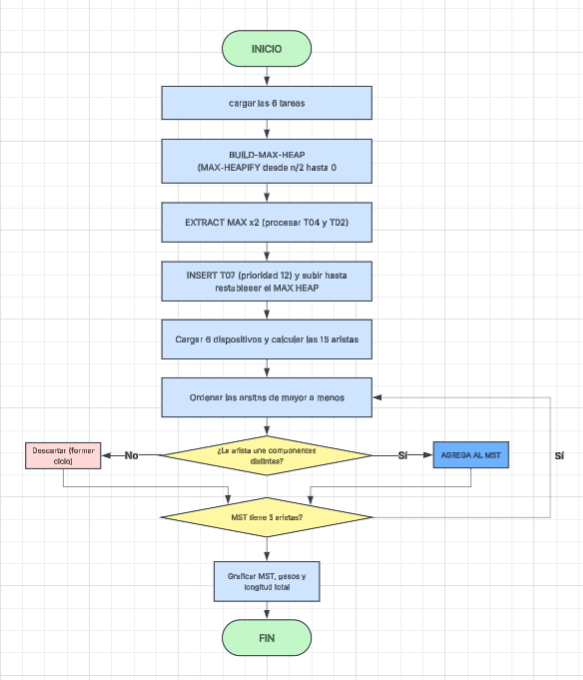

### 5) Análisis de complejidad **[15 pts]**
**Justificación.** **m** el número de tareas del heap, V el número de dispositivos. h = log2 n  su altura, E = V(V-1)/2 el número de aristas del grafo completo. 
El heap guarda en un arreglo:
   
                                El derecho 2i+2. 

                                El hijo izquierdo de i es 2i+1

                                El padre  (i-1)

 - Mejor caso (el arreglo ya es un Max-Heap, por ejemplo en orden descendente): No hay intercambios,  el algoritmo se encarga de hacer solo las comparaciones, es decir. Para $n=6$, hace 6 comparaciones como mínimo.
- Peor caso (arreglo en orden ascendente, cada nodo desciende hasta una hoja):  con unas $3n$ operaciones (comparaciones más intercambios) como máximo.

 EXTRACT-MAX Mueve la última hoja a la raíz y ejecuta MAX-HEAPIFY:
- Peor caso: prioridades iguales
 INSERT Agrega al final y sube mientras el padre sea menor.
- Peor caso: Nueva prioridad mayor, sube hasta la raiz
 
En cuanto al algoritmo de Kruskal, primero se ordenan las aristas según su peso, lo que tiene un costo de .
 
Luego, se recorren las aristas utilizando la estructura Union-Find, que aplica compresión de caminos y unión por rango, haciendo que esta parte del proceso sea prácticamente lineal.
 
Para , se tienen aristas. El algoritmo termina cuando se han seleccionado aristas que forman el árbol de expansión mínima.
 
En el mejor caso, el tiempo de ejecución sigue siendo , ya que la ordenación inicial siempre se realiza. Aunque el recorrido puede terminar antes, cuando las 5 aristas de menor peso forman el árbol, el costo de ordenar las aristas se mantiene.


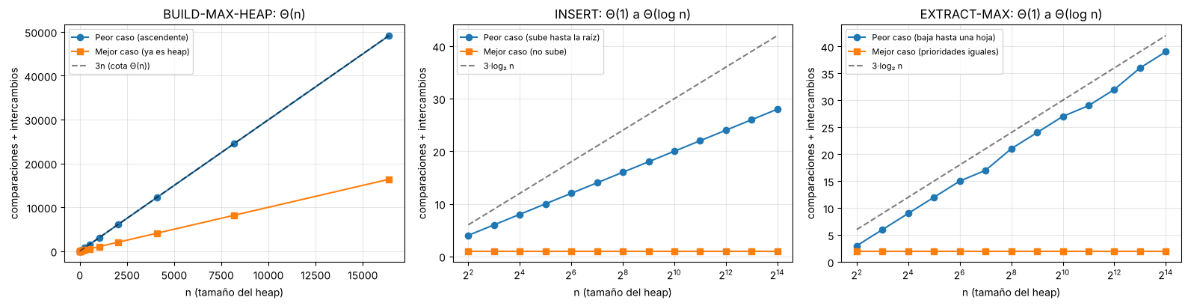
 


## 6) Código funcional **[15 pts]**



## 7) Tests aplicados **[15 pts]**